## Convolutional Neural Network

In [1]:
# Import libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [2]:
# Define dataset paths
DATASET_PATH = Path("../dataset/cell_images")

parasitized_path = DATASET_PATH / "Parasitized"
uninfected_path = DATASET_PATH / "Uninfected"

print("Parasitized folder exists:",
      parasitized_path.exists())

print("Uninfected folder exists:",
      uninfected_path.exists())

Parasitized folder exists: False
Uninfected folder exists: False


In [8]:
parasitized_images = [
    f for f in parasitized_path.iterdir()
    if f.suffix.lower() in [".png", ".jpg", ".jpeg"]
]

uninfected_images = [
    f for f in uninfected_path.iterdir()
    if f.suffix.lower() in [".png", ".jpg", ".jpeg"]
]

print("Parasitized images:", len(parasitized_images))
print("Uninfected images:", len(uninfected_images))

total_images = (
    len(parasitized_images) +
    len(uninfected_images)
)

print("Total images:", total_images)

Parasitized images: 13779
Uninfected images: 13779
Total images: 27558


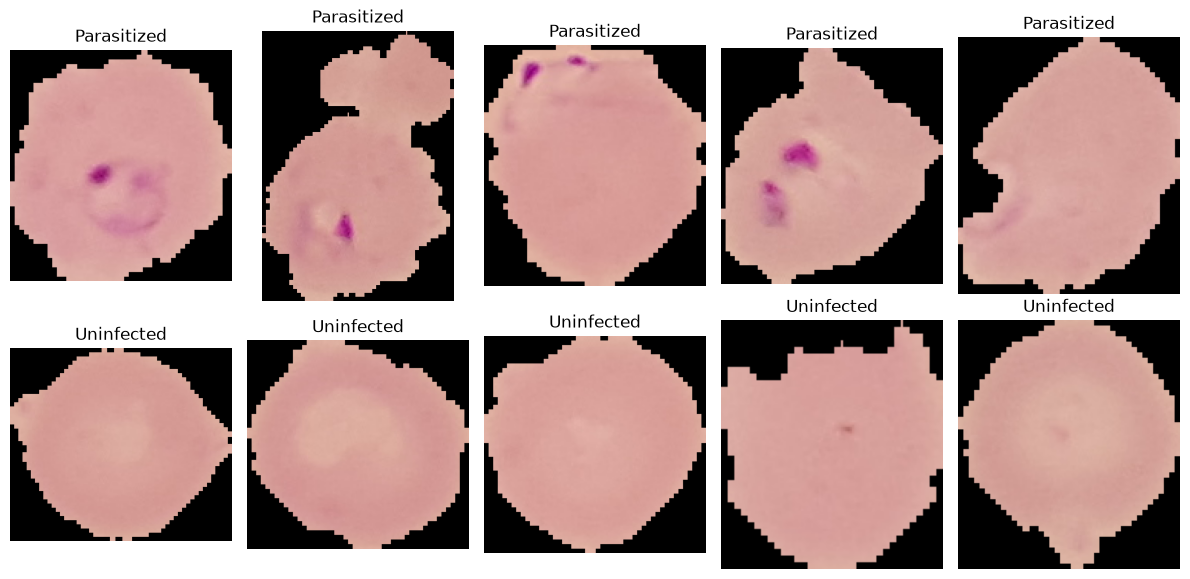

In [9]:
plt.figure(figsize=(12, 6))

for i in range(5):

    # Parasitized image
    img1 = Image.open(parasitized_images[i])

    plt.subplot(2, 5, i + 1)
    plt.imshow(img1)
    plt.title("Parasitized")
    plt.axis("off")

    # Uninfected image
    img2 = Image.open(uninfected_images[i])

    plt.subplot(2, 5, i + 6)
    plt.imshow(img2)
    plt.title("Uninfected")
    plt.axis("off")

plt.tight_layout()
plt.show()

Image Preprocessing

In [10]:
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: 224
Batch size: 32


In [11]:
import pandas as pd

image_paths = []
labels = []

for img in parasitized_images:
    image_paths.append(str(img))
    labels.append(1)

for img in uninfected_images:
    image_paths.append(str(img))
    labels.append(0)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print(df.head())
print("\nTotal images:", len(df))

                                          image_path  label
0  c:\Users\Sanna Sharma\Desktop\Projectml\Malari...      1
1  c:\Users\Sanna Sharma\Desktop\Projectml\Malari...      1
2  c:\Users\Sanna Sharma\Desktop\Projectml\Malari...      1
3  c:\Users\Sanna Sharma\Desktop\Projectml\Malari...      1
4  c:\Users\Sanna Sharma\Desktop\Projectml\Malari...      1

Total images: 27558


In [12]:
print(df["label"].value_counts())

label
1    13779
0    13779
Name: count, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

# First: 70% training, 30% remaining
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

# Second: divide remaining 30% equally in validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 19290
Validation images: 4134
Testing images: 4134


In [14]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    return image, tf.cast(label, tf.float32)

In [15]:
def create_dataset(dataframe, training=False):

    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=1000,
            seed=SEED
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset

In [16]:
train_ds = create_dataset(train_df, training=True)

val_ds = create_dataset(val_df)

test_ds = create_dataset(test_df)

print("All datasets created successfully!")

All datasets created successfully!


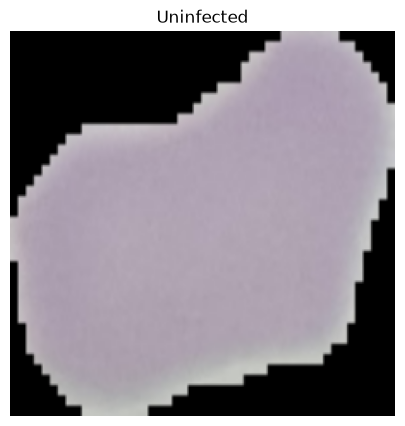

In [17]:
for images, labels in train_ds.take(1):

    plt.figure(figsize=(5, 5))

    plt.imshow(
        images[0].numpy().astype("uint8")
    )

    label = int(labels[0].numpy())

    class_name = (
        "Parasitized" if label == 1
        else "Uninfected"
    )

    plt.title(class_name)
    plt.axis("off")
    plt.show()

Building Convolutional Neural Network

In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    Rescaling
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

In [19]:
model = Sequential([

    # Input and normalization
    tf.keras.Input(shape = (224, 224, 3)),
    Rescaling(1./255),

    # First convolution block
    Conv2D(32, (3, 3), activation = 'relu'),
    MaxPooling2D(2, 2),

    # Second convolution block
    Conv2D(64, (3, 3), activation = 'relu'),
    MaxPooling2D(2, 2),

    # Third convolution block
    Conv2D(128, (3, 3), activation = 'relu'),
    MaxPooling2D(2, 2),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

In [20]:
model.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
os.makedirs("../models", exist_ok=True)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "../models/best_cnn.keras",
    monitor='val_loss',
    save_best_only=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

In [23]:
history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15,

    callbacks=[
        early_stop,
        checkpoint,
        reduce_lr
    ]
)

Epoch 1/15


c:\Users\Sanna Sharma\Desktop\Projectml\Malaria_Project\.venv312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


603/603 ━━━━━━━━━━━━━━━━━━━━ 359s 591ms/step - accuracy: 0.8404 - auc: 0.9196 - loss: 0.3857 - precision: 0.8710 - recall: 0.7991 - val_accuracy: 0.9432 - val_auc: 0.9749 - val_loss: 0.1940 - val_precision: 0.9486 - val_recall: 0.9371 - learning_rate: 0.0010
Epoch 2/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 315s 521ms/step - accuracy: 0.9396 - auc: 0.9778 - loss: 0.1778 - precision: 0.9448 - recall: 0.9336 - val_accuracy: 0.9480 - val_auc: 0.9824 - val_loss: 0.1852 - val_precision: 0.9469 - val_recall: 0.9492 - learning_rate: 0.0010
Epoch 3/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 318s 528ms/step - accuracy: 0.9473 - auc: 0.9827 - loss: 0.1548 - precision: 0.9574 - recall: 0.9362 - val_accuracy: 0.9463 - val_auc: 0.9817 - val_loss: 0.1730 - val_precision: 0.9408 - val_recall: 0.9526 - learning_rate: 0.0010
Epoch 4/15
603/603 ━━━━━━━━━━━━━━━━━━━━ 318s 527ms/step - accuracy: 0.9537 - auc: 0.9873 - loss: 0.1336 - precision: 0.9648 - recall: 0.9417 - val_accuracy: 0.9494 - val_auc: 0.9840 - val_loss: 0.1792 

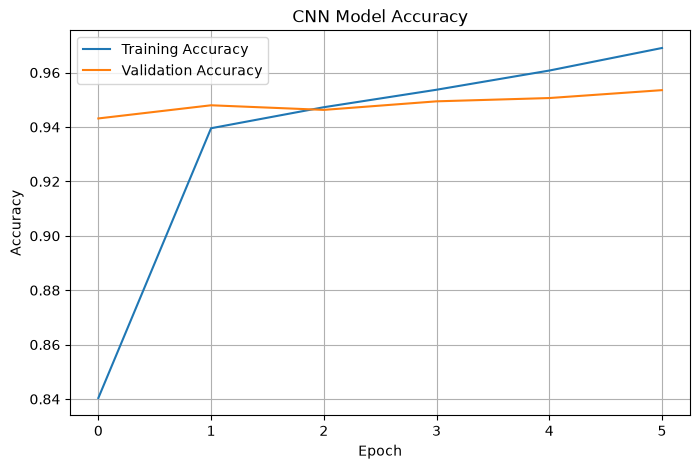

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid()
plt.show()

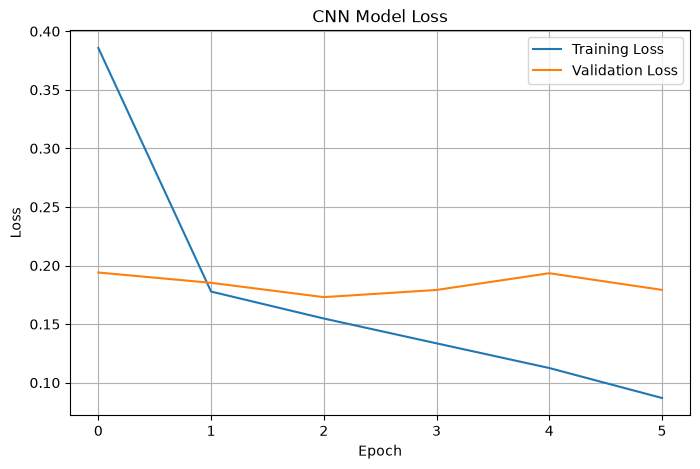

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid()
plt.show()

In [26]:
print("Epochs completed:", len(history.history['loss']))

print("Early stopping triggered at:",
      early_stop.stopped_epoch)

print("Best validation loss:",
      min(history.history['val_loss']))

print("Best epoch:",
      history.history['val_loss'].index(
          min(history.history['val_loss'])
      ) + 1)

Epochs completed: 6
Early stopping triggered at: 5
Best validation loss: 0.17302896082401276
Best epoch: 3


In [27]:
for i in range(len(history.history['loss'])):

    print(
        f"Epoch {i+1}: "
        f"Training Accuracy = {history.history['accuracy'][i]:.4f}, "
        f"Validation Accuracy = {history.history['val_accuracy'][i]:.4f}, "
        f"Validation Loss = {history.history['val_loss'][i]:.4f}"
    )

Epoch 1: Training Accuracy = 0.8404, Validation Accuracy = 0.9432, Validation Loss = 0.1940
Epoch 2: Training Accuracy = 0.9396, Validation Accuracy = 0.9480, Validation Loss = 0.1852
Epoch 3: Training Accuracy = 0.9473, Validation Accuracy = 0.9463, Validation Loss = 0.1730
Epoch 4: Training Accuracy = 0.9537, Validation Accuracy = 0.9494, Validation Loss = 0.1792
Epoch 5: Training Accuracy = 0.9608, Validation Accuracy = 0.9507, Validation Loss = 0.1934
Epoch 6: Training Accuracy = 0.9691, Validation Accuracy = 0.9536, Validation Loss = 0.1792


In [28]:
test_results = model.evaluate(test_ds, verbose=1)

for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

130/130 ━━━━━━━━━━━━━━━━━━━━ 15s 111ms/step - accuracy: 0.9434 - auc: 0.9813 - loss: 0.1711 - precision: 0.9408 - recall: 0.9463
loss: 0.1711
compile_metrics: 0.9434


In [29]:
import numpy as np

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = model.predict(test_ds)

y_pred = (y_prob.flatten() >= 0.5).astype(int)

print("Actual labels:", y_true[:10])
print("Predicted labels:", y_pred[:10])

130/130 ━━━━━━━━━━━━━━━━━━━━ 12s 95ms/step
Actual labels: [0. 1. 0. 1. 0. 0. 0. 1. 1. 0.]
Predicted labels: [0 1 0 1 0 0 0 1 1 0]


In [30]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Uninfected", "Parasitized"]
))

              precision    recall  f1-score   support

  Uninfected       0.95      0.94      0.94      2067
 Parasitized       0.94      0.95      0.94      2067

    accuracy                           0.94      4134
   macro avg       0.94      0.94      0.94      4134
weighted avg       0.94      0.94      0.94      4134



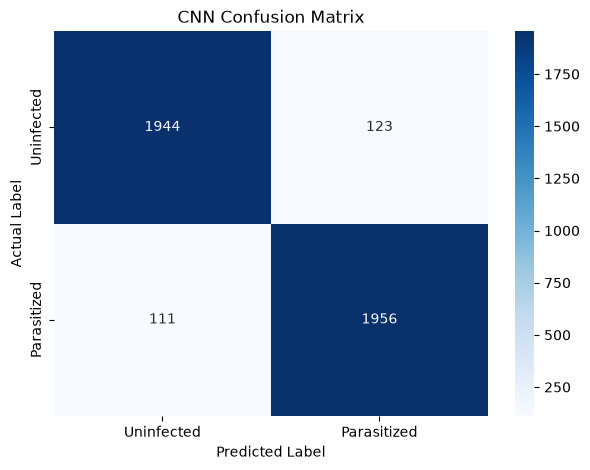

In [31]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Confusion Matrix")

plt.show()

ROC-AUC Score: 0.982620786150649


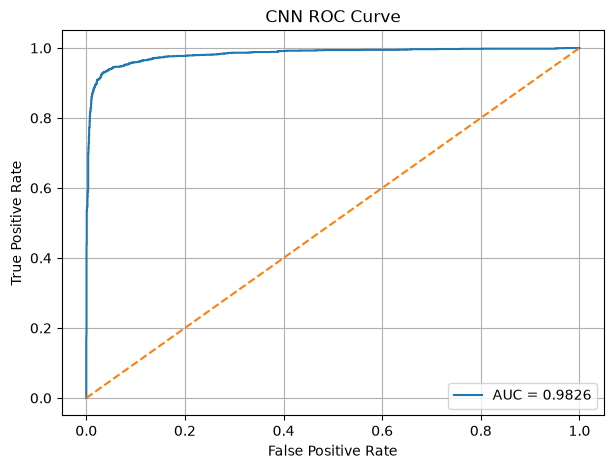

In [32]:
from sklearn.metrics import roc_auc_score, roc_curve

auc_score = roc_auc_score(y_true, y_prob.flatten())

print("ROC-AUC Score:", auc_score)

fpr, tpr, thresholds = roc_curve(y_true, y_prob.flatten())

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN ROC Curve")

plt.legend()
plt.grid()
plt.show()

In [33]:
model.save("../models/malaria_cnn_final.keras")

print("CNN model saved successfully!")

CNN model saved successfully!
